<a href="https://colab.research.google.com/github/mkaabduljaleelhinan-pixel/jaleel-hinan-DL-unit/blob/main/SMS_Spam_Detection_LSTM_Updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files

uploaded = files.upload()

Saving spam_sms.csv to spam_sms.csv


In [3]:
import pandas as pd
import io

filename = next(iter(uploaded))
file_bytes = io.BytesIO(uploaded[filename])
df = pd.read_csv(file_bytes, sep=None, engine="python", on_bad_lines="skip")
if len(df.columns) == 1:
    for delimiter in ["\t", ",", ";"]:
        file_bytes.seek(0)
        candidate = pd.read_csv(file_bytes, sep=delimiter, on_bad_lines="skip")
        if len(candidate.columns) > 1:
            df = candidate
            break

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())

Dataset shape: (5572, 2)
Column names: ['v1', 'v2']


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
df.columns = df.columns.str.strip().str.lower()

print("Available columns:", df.columns.tolist())

Available columns: ['v1', 'v2']


In [5]:
text_candidates = ["message", "text", "sms", "v2", "message_text", "sms_text"]
label_candidates = ["label", "category", "type", "class", "v1", "target"]

text_col = next((c for c in text_candidates if c in df.columns), None)
label_col = next((c for c in label_candidates if c in df.columns), None)

if text_col is None or label_col is None:
    raise ValueError(
        "Could not automatically identify message and label columns. "
        f"Available columns: {df.columns.tolist()}. "
        "Edit text_candidates/label_candidates to match your dataset."
    )

df = df[[text_col, label_col]].copy()
df.columns = ["message", "label"]

print("Detected message column:", text_col)
print("Detected label column:", label_col)
display(df.head())
print("\nOriginal label counts:")
print(df["label"].value_counts(dropna=False))

Detected message column: v2
Detected label column: v1


,message,label
0,"Go until jurong point, crazy.. Available only ...",ham
1,Ok lar... Joking wif u oni...,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,spam
3,U dun say so early hor... U c already then say...,ham
4,"Nah I don't think he goes to usf, he lives aro...",ham



Original label counts:
label
ham     4825
spam     747
Name: count, dtype: int64


In [6]:
# Remove rows with missing message/label values and normalize common label names.
df = df.dropna(subset=["message", "label"]).copy()
df["message"] = df["message"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.strip().str.lower()

df = df[(df["message"] != "") & (df["label"] != "")].copy()

label_map = {
    "ham": "ham",
    "spam": "spam",
    "0": "ham",
    "1": "spam",
    "normal": "ham",
    "legitimate": "ham",
    "not spam": "ham",
    "junk": "spam"
}
df["label"] = df["label"].map(label_map)
df = df.dropna(subset=["label"])
df = df.drop_duplicates(subset=["message", "label"]).reset_index(drop=True)

if df["label"].nunique() != 2:
    raise ValueError(
        "After label cleaning, both ham and spam labels must be present. "
        f"Labels found: {df['label'].value_counts().to_dict()}"
    )

print("Clean dataset shape:", df.shape)
print("Missing values after cleaning:")
print(df.isna().sum())
print("\nClean label counts:")
print(df["label"].value_counts())

Clean dataset shape: (5158, 2)
Missing values after cleaning:
message    0
label      0
dtype: int64

Clean label counts:
label
ham     4516
spam     642
Name: count, dtype: int64


In [7]:
N_SAMPLES = min(2000, len(df))

if N_SAMPLES < 2:
    raise ValueError("The dataset must contain at least two valid messages.")

df = df.sample(
    n=N_SAMPLES,
    random_state=42
).reset_index(drop=True)

print("Selected samples:", len(df))
print(df["label"].value_counts())

Selected samples: 2000
label
ham     1740
spam     260
Name: count, dtype: int64


In [8]:
import re

def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Replace repeated whitespace with one space
    text = re.sub(r"\s+", " ", text)

    # Remove leading and trailing spaces
    text = text.strip()

    return text

df["message"] = df["message"].apply(preprocess_text)

print(df[["message", "label"]].head())

                                             message label
0       &lt;#&gt; am i think? should say on syllabus   ham
1     2mro i am not coming to gym machan. goodnight.   ham
2  carlos'll be here in a minute if you still nee...   ham
3    id onluy matters when getting on from offcampus   ham
4             except theres a chick with huge boobs.   ham


In [9]:
from sklearn.model_selection import train_test_split

X = df["message"].values
y = df["label"].map({"ham": 0, "spam": 1}).values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 1600
Testing messages: 400


In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 10000
MAX_LEN = 80
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)
tokenizer.fit_on_texts(X_train)
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)
print("Vocabulary size:", len(tokenizer.word_index))

Training shape: (1600, 80)
Testing shape: (400, 80)
Vocabulary size: 4545


In [11]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)


vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)


model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64, dropout=0.2),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])


model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.8463 - loss: 0.5207 - val_accuracy: 0.8958 - val_loss: 0.2598 - learning_rate: 0.0010
Epoch 2/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9551 - loss: 0.1508 - val_accuracy: 0.9917 - val_loss: 0.0510 - learning_rate: 0.0010
Epoch 3/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9934 - loss: 0.0330 - val_accuracy: 0.9917 - val_loss: 0.0475 - learning_rate: 0.0010
Epoch 4/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9971 - loss: 0.0160 - val_accuracy: 0.9958 - val_loss: 0.0177 - learning_rate: 0.0010
Epoch 5/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 1.0000 - loss: 0.0052 - val_accuracy: 1.0000 - val_loss: 0.0096 - learning_rate: 0.0010
Epoch 6/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 1.0000 - loss: 0.0021 - val_accuracy: 0.9958 - val_loss: 0.0173 - learning_rate: 0.0010
Epoch 7/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 1.0000 - loss: 0.0015 - val_acc

In [13]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_prob = model.predict(X_test_pad, verbose=0).ravel()

y_pred = (y_prob >= 0.5).astype(int)
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

recall = recall_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))

Accuracy : 0.9875
Precision: 0.9608
Recall   : 0.9423
F1-score : 0.9515

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       348
        Spam       0.96      0.94      0.95        52

    accuracy                           0.99       400
   macro avg       0.98      0.97      0.97       400
weighted avg       0.99      0.99      0.99       400



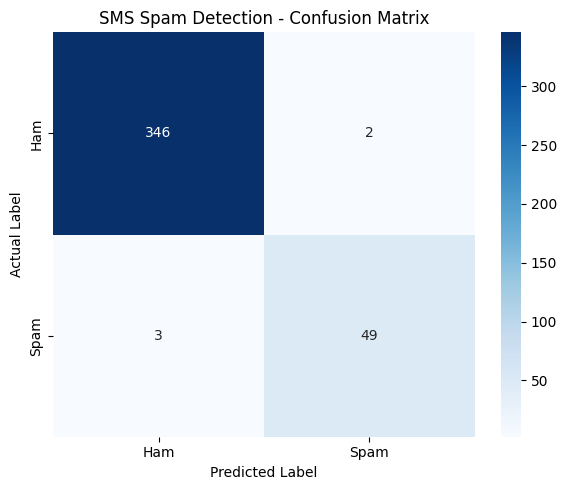

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.tight_layout()
plt.show()

In [15]:
unseen_messages = [
    "Hey, are we meeting for lunch today?",
    "Congratulations! You have won a free prize. Call now!",
    "URGENT! Claim your cash reward by clicking this link!",
    "Can you send me the notes from today's class?",
    "You have been selected for a free gift. Reply now to claim!"
]


unseen_clean = [
    preprocess_text(message)
    for message in unseen_messages
]


unseen_seq = tokenizer.texts_to_sequences(unseen_clean)


unseen_pad = pad_sequences(
    unseen_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)


unseen_prob = model.predict(unseen_pad, verbose=0).ravel()


for message, probability in zip(unseen_messages, unseen_prob):
    predicted_label = "SPAM" if probability >= 0.5 else "HAM"

    print("Message:", message)
    print("Prediction:", predicted_label)
    print(f"Spam probability: {probability:.2%}")
    print("-" * 60)

Message: Hey, are we meeting for lunch today?
Prediction: HAM
Spam probability: 0.04%
------------------------------------------------------------
Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
Spam probability: 99.58%
------------------------------------------------------------
Message: URGENT! Claim your cash reward by clicking this link!
Prediction: SPAM
Spam probability: 99.06%
------------------------------------------------------------
Message: Can you send me the notes from today's class?
Prediction: HAM
Spam probability: 0.02%
------------------------------------------------------------
Message: You have been selected for a free gift. Reply now to claim!
Prediction: SPAM
Spam probability: 98.77%
------------------------------------------------------------


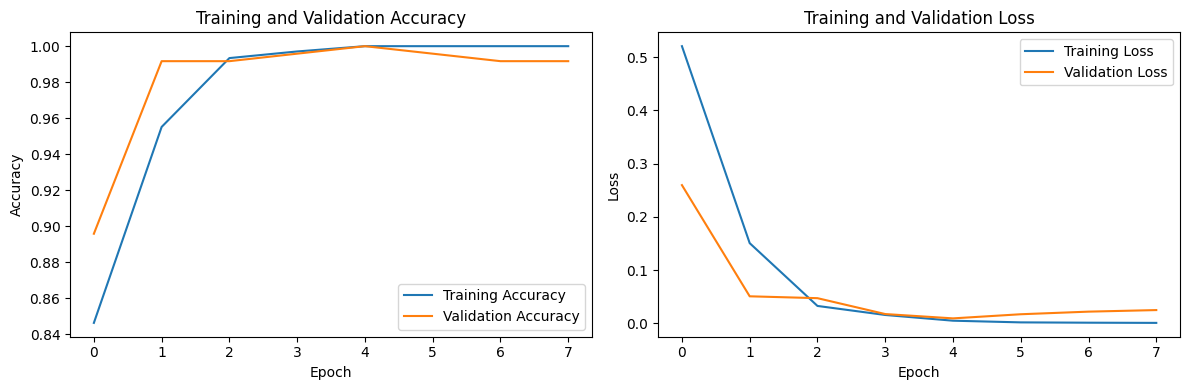

In [16]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
from sklearn.metrics import accuracy_score

# Predict the test messages
y_prob = model.predict(X_test_pad, verbose=0).ravel()

# Convert probabilities to HAM (0) or SPAM (1)
y_pred = (y_prob >= 0.5).astype(int)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 98.75 %


In [18]:
message = input("Enter an SMS message to check: ")

cleaned_message = preprocess_text(message)

sequence = tokenizer.texts_to_sequences([cleaned_message])

padded_message = pad_sequences(
    sequence,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

spam_probability = model.predict(
    padded_message, verbose=0
)[0][0]

if spam_probability >= 0.5:
    print("Prediction: SPAM")
else:
    print("Prediction: HAM")

print(f"Spam Probability: {spam_probability * 100:.2f}%")

Enter an SMS message to check: hi 678t hinan
Prediction: HAM
Spam Probability: 22.32%
